In [1]:
# API 키를 환경변수로 관리하기 위한 설정 파일
from dotenv import load_dotenv

# API 키 정보 로드
load_dotenv()
# https://wikidocs.net/264614 

True

In [2]:
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages


# State 정의
class State(TypedDict):
    # list 타입에 add_messages 적용(list 에 message 추가)
    messages: Annotated[list, add_messages]

In [3]:
# !pip install langchain-ollama

In [3]:
# from langchain_openai import ChatOpenAI
# from langchain_community.chat_models import ChatOllama
import os
# [참고] 기존: from langchain_ollama import ChatOllama
from langchain_openai import ChatOpenAI
# from langchain_ollama import ChatOllama

# LLM 초기화
# llm = ChatOpenAI(api_key="ollama", model="mistral:latest", base_url="http://61.108.166.16:11434")
# llm = ChatOpenAI(model="gpt-4o-mini")
# llm = ChatOllama(model="mistral:latest", base_url="http://61.108.166.16:11434")
# llm = ChatOllama(model="mistral:latest", temperature=0, base_url = "http://192.168.1.203:11434")
# [참고] 기존: llm = ChatOllama(model="mistral:latest", temperature=0)
# OpenRouter Gemma 4 26B A4B 사용 (OPENROUTER_API_KEY 필요)
llm = ChatOpenAI(
    model=os.getenv("OPENROUTER_MODEL", "google/gemma-4-26b-a4b-it"),
    api_key=os.getenv("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1",
    temperature=0,
)
# llm = ChatOllama(model="mistral:latest", base_url="http://ollama_dev:11434")


In [4]:
question = "서울의 유명한 맛집 TOP 10 추천해줘"
llm.invoke(question)

AIMessage(content="서울은 워낙 맛집이 많아 'TOP 10'을 선정하는 것이 매우 어렵지만, **현지인과 관광객 모두에게 검증된, 특정 메뉴로 상징성이 있는 곳들**을 기준으로 10곳을 엄선해 추천해 드립니다.\n\n분야별로 나누어 정리해 드렸으니 취향에 맞춰 방문해 보세요!\n\n---\n\n### 1. 한식 & 고기 (전통과 깊은 맛)\n\n*   **① 우래옥 (을지로/중구)**\n    *   **주요 메뉴:** 평양냉면\n    *   **특징:** 한국 평양냉면의 성지 중 하나입니다. 깊고 진한 육수 맛이 일품이며, 냉면뿐만 아니라 불고기도 매우 유명합니다.\n*   **② 금돼지식당 (약수역/중구)**\n    *   **주요 메뉴:** 돼지고기 구이 (본삼겹, 눈꽃목살)\n    *   **특징:** 미쉐린 가이드 빕 구르망에 선정된 곳으로, 두툼한 고기의 육즙과 고소한 맛이 일품입니다. 웨이팅이 길지만 그만한 가치가 있습니다.\n*   **③ 명동교자 (명동/중구)**\n    *   **주요 메뉴:** 칼국수, 만두\n    *   **특식:** 미쉐린 가이드에 매년 이름을 올리는 곳입니다. 진한 닭 육수와 부드러운 면발, 그리고 알싸한 마늘 김치가 환상적인 조화를 이룹니다.\n\n### 2. 노포 & 로컬 맛집 (오랜 전통의 맛)\n\n*   **④ 광화문 미진 (광화문/종로)**\n    *   **주요 메뉴:** 메밀국수 (판모밀)\n    *   **특징:** 여름철 서울에서 가장 유명한 메밀국수 집 중 하나입니다. 시원하고 깔끔한 육수가 특징입니다.\n*   **⑤ 을지로 쇄가 (을지로/중구)**\n    *   **주요 메뉴:** 족발, 보쌈 (또는 을지로 일대 노포들)\n    *   **특징:** 을지로 특유의 '힙지로' 감성과 함께 노포의 정취를 느낄 수 있는 곳들이 많습니다. (최근 트렌디한 곳을 원하신다면 을지로 일대를 추천합니다.)\n\n### 3. 트렌디 & 퓨전 (MZ세대 인기 맛집)\n\n*   **⑥

In [5]:
# 챗봇 함수 정의
def chatbot(state: State):
    # 메시지 호출 및 반환
    return {"messages": [llm.invoke(state["messages"])]}

In [6]:
# 그래프 생성 및 노드를 추가
from langgraph.graph import StateGraph, START, END

# 상태 그래프 초기화
graph_builder = StateGraph(State)

# 노드 추가
graph_builder.add_node("chatbot", chatbot)

In [7]:
# 시작 노드에서 챗봇 노드로의 엣지 추가
graph_builder.add_edge(START, "chatbot")
# 그래프에 엣지 추가
graph_builder.add_edge("chatbot", END)

In [8]:
# 그래프 컴파일
graph = graph_builder.compile()

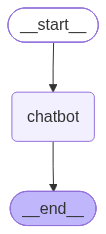

In [9]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
question = "부산역 근처의 유명한 맛집 TOP 10 추천해줘"

# 그래프 이벤트 스트리밍
for event in graph.stream({"messages": [("user", question)]}):
    # 이벤트 값 출력
    for value in event.values():
        print("Assistant:", value["messages"][-1].content)

Assistant: 부산역 근처(초량동, 중앙동, 부산역 인근)는 부산의 관문답게 노포 맛집부터 현대적인 맛집까지 아주 다양합니다. 현지인과 관광객 모두에게 사랑받는 **부산역 근처 맛집 TOP 10**을 카테고리별로 나누어 추천해 드립니다.

### 1. 부산의 소울푸드 (돼지국밥 & 밀면)
*   **본전돼지국밥:** 부산역 바로 옆에 위치하여 여행객들이 가장 많이 찾는 곳 중 하나입니다. 맑고 깔끔한 국물 맛이 특징이며, 잡내가 적어 입문자에게도 좋습니다.
*   **초량밀면:** 부산에 오면 꼭 먹어야 하는 밀면 맛집입니다. 새콤달콤한 양념과 시원한 육수가 일품이며, 만두와 함께 곁들여 먹는 것을 추천합니다.

### 2. 부산의 별미 (낙곱채 & 해산물)
*   **개미집 (본점/분점):** 낙지, 곱창, 채소를 매콤하게 볶아 먹는 '낙곱채'의 원조 격인 곳입니다. 밥에 슥슥 비벼 먹는 맛이 일품입니다.
*   **신발원:** 부산역 앞 차이나타운에 위치한 만두 맛집입니다. 백종원의 3대 천왕 등 여러 방송에 소개되었으며, 육즙이 가득한 군만두와 찐만두가 매우 유명합니다. (웨이팅이 길 수 있습니다.)

### 3. 든든한 한 끼 (정식 & 밥집)
*   **초량 1941:** 오래된 적산가옥을 개조한 카페 겸 디저트 맛집이지만, 근처에 정갈한 한식당들이 많아 식사 후 들르기 좋습니다.
*   **동구식당:** 현지인들이 즐겨 찾는 백반 맛집으로, 집밥 같은 정갈하고 푸짐한 반찬을 맛볼 수 있습니다.

### 4. 면 요리 & 기타
*   **중앙모밀:** 중앙동 인근에서 유명한 곳으로, 깔끔한 메밀국수와 돈가스 조합이 좋습니다. 점심시간에는 직장인들로 매우 붐빕니다.
*   **부평동/중앙동 일대 횟집:** 부산역에서 조금만 이동하면 부산의 싱싱한 회를 즐길 수 있는 노포 횟집들이 밀집해 있습니다.

### 5. 디저트 & 카페
*   **브라운핸즈 백제:** 부산역 인근의 오래된 건물을 개조한 카페로, 빈티지한 분위기 속에서 커피를 즐길 수 있어 